# FeliX：PySD 求解与绘图
加载同目录的 `FeliX3_ISE_v26_final_fixed.py`，按原模型步长 0.125 年运行 1900–2100，每年保存一次。中文说明、英文图题，避免字体依赖。

依赖：`pysd numpy pandas xarray matplotlib ipykernel`（本次运行使用 PySD 3.9.0；模型由 3.14.3 翻译）。选择已安装这些包的 Python 内核，顺序运行即可。结果 `result` 保留全部性别、年龄、食品类型下标；英文名与 Python 名是同一个变量，无须重复求解。

In [ ]:
%matplotlib inline
import warnings
warnings.simplefilter("once", UserWarning)
from pathlib import Path
from time import perf_counter
import numpy as np
import pandas as pd
import xarray as xr
import pysd
import matplotlib.pyplot as plt
from IPython.display import display

# 从 notebook 所在目录启动；也支持从项目根目录启动。
model_path = (Path("output") / "FeliX3_ISE_v26_final_fixed.py").resolve()

model = pysd.load(model_path)
c = model.components

print(f"PySD {pysd.__version__} | {model_path.resolve()}")
print(f"Time: {c.initial_time()}–{c.final_time()}, dt={c.time_step()}")

PySD 3.14.3 | F:\BaiduSyncdisk-mu\Project ITP\tool-for-scientific-research\1_felix-pysd\output\FeliX3_ISE_v26_final_fixed.py
Time: 1900–2100, dt=0.125


f:\BaiduSyncdisk-mu\Project ITP\tool-for-scientific-research\1_felix-pysd\.venv\Lib\site-packages\pysd\py_backend\lookups.py:108: UserWarning: _hardcodedlookup_lookup_for_the_impact_of_mys_on_climate_mortality
extrapolating data below the minimum value of the series
  warnings.warn(
f:\BaiduSyncdisk-mu\Project ITP\tool-for-scientific-research\1_felix-pysd\.venv\Lib\site-packages\pysd\py_backend\lookups.py:108: UserWarning: _hardcodedlookup_effect_of_t_on_yield_lookup
extrapolating data below the minimum value of the series
  warnings.warn(


## 1. 变量名称
使用 Python 名请求输出，表中同时给出原模型英文名。

In [ ]:
variables = {
    "Labor Force Participation Fraction Variation": "labor_force_participation_fraction_variation",
    "Birth Gender Fraction": "birth_gender_fraction",
    "Production rate of animal food": "production_rate_of_animal_food",
    "Survivors at exact age x": "survivors_at_exact_age_x",
    "Total person years T": "total_person_years_t",
    "Total person years of interest pT": "total_person_years_of_interest_pt",
    "Total person years of interest pT POVERTY": "total_person_years_of_interest_pt_poverty",
    "Total person years of interest pT HEALTH": "total_person_years_of_interest_pt_health",
    "Total person years of interest pT EDUCATION": "total_person_years_of_interest_pt_education",
}
display(pd.Series(variables, name="Python name").rename_axis("Model name").to_frame())


,Python name
Model name,
Labor Force Participation Fraction Variation,labor_force_participation_fraction_variation
Birth Gender Fraction,birth_gender_fraction
Production rate of animal food,production_rate_of_animal_food
Survivors at exact age x,survivors_at_exact_age_x
Total person years T,total_person_years_t
Total person years of interest pT,total_person_years_of_interest_pt
Total person years of interest pT POVERTY,total_person_years_of_interest_pt_poverty
Total person years of interest pT HEALTH,total_person_years_of_interest_pt_health
Total person years of interest pT EDUCATION,total_person_years_of_interest_pt_education


## 2. 消除生命表的数组递归
原翻译代码中，`Survivors at exact age x` 和五个 `Total person years…` 函数调用自身，会导致 `RecursionError`。这里仅在内存中替换这六个函数，不修改源文件，也不添加劳动力等其他定义补丁。

- 存活人数：最年轻组保持 `Actual Survivors in 2000` 的边界值；2000 年前年长组为零，2000 年起按 `l[x+1] = l[x] * (1-q[x])` 递推，用累计乘积实现。
- 总人年：保留最老组边界，按 `T[x] = L[x] + T[x+1]` 从老到少反向累计求和。pT 的四种情况分别使用对应的 pLi。

这些是年龄下标递推，不是时间积分。保留原 STEP 在 2000 年开启的定义，因此此前的生命表输出不宜直接解释为常规完整生命表；此处不代表已与 Vensim 数值对照验证。

In [ ]:
def survivors_at_exact_age_x():
    # 年龄组按从年轻到年老排列，例如 0–4、5–9、……、100+。
    cohorts = model.subscripts["Cohorts"]
    youngest = cohorts[0]

    # 创建全零结果，并填入最年轻组的边界人数。
    initial_survivors = c.actual_survivors_in_2000() # C 表示相关的组件信息，获取结果值，返回的是 xarray.DataArray (即带有维度名称和坐标标签的多维数组)
    boundary = initial_survivors.sel(Cohorts=youngest, drop=True) # 根据标签选数据，选择 cohorts 维度上 youngest 对应的值，drop=True 表示不再保留所选年龄组的那个单独坐标标签,只有 gender
    survivors = xr.zeros_like(initial_survivors) # 创建一个类似的全新数组分支
    
    survivors.loc[{"Cohorts": youngest}] = boundary # 把 新构造数组替换为 boundary, 像是 copy 

    # 保留原模型定义：2000 年前年长组均为零。
    if model.time() < 2000:
        return survivors

    # 每个区间的存活概率 = 1 - 该区间死亡概率。
    death_probability = c.probability_of_dying_in_the_interval()
    death_probability = death_probability.transpose("Gender", "Cohorts")
    survival_probability = 1 - death_probability.values[:, :-1]

    # 沿年龄组累计相乘，例如 [0.9, 0.8] → [0.9, 0.72]。
    cumulative_survival = np.cumprod(survival_probability, axis=1)

    # 男女分别乘各自的边界人数；最老组后面没有年龄组，故不使用其概率。
    starting_population = boundary.values.reshape(-1, 1)
    survivors.values[:, 1:] = starting_population * cumulative_survival
    return survivors


def reverse_cohort_sum(person_years):
    # 例如：年轻到年老的人年为 [10, 20, 30]。
    cohorts = person_years.coords["Cohorts"].values # 重新定位取值

    # 第一步：倒转年龄顺序，得到 [30, 20, 10]。
    oldest_first = person_years.reindex(Cohorts=cohorts[::-1])

    # 第二步：从最老组向年轻组累计，得到 [30, 50, 60]。
    accumulated = oldest_first.cumsum("Cohorts")

    # 第三步：恢复原年龄顺序，得到 [60, 50, 30]。
    return accumulated.reindex(Cohorts=cohorts)


def total_person_years_t():
    # 累计各年龄组的全部人年。
    person_years = c.person_years_lived_in_interval_i()
    return reverse_cohort_sum(person_years)


def total_person_years_of_interest_pt():
    # 累计各年龄组满足综合条件的人年。
    person_years = c.person_years_of_interest_pli()
    return reverse_cohort_sum(person_years)


def total_person_years_of_interest_pt_poverty():
    # 累计各年龄组对应贫困指标的人年。
    person_years = c.person_years_of_interest_pli_poverty()
    return reverse_cohort_sum(person_years)


def total_person_years_of_interest_pt_health():
    # 累计各年龄组对应健康指标的人年。
    person_years = c.person_years_of_interest_pli_health()
    return reverse_cohort_sum(person_years)


def total_person_years_of_interest_pt_education():
    # 累计各年龄组对应教育指标的人年。
    person_years = c.person_years_of_interest_pli_education()
    return reverse_cohort_sum(person_years)


model.set_components({
    "survivors_at_exact_age_x": survivors_at_exact_age_x,
    "total_person_years_t": total_person_years_t,
    "total_person_years_of_interest_pt": total_person_years_of_interest_pt,
    "total_person_years_of_interest_pt_poverty": total_person_years_of_interest_pt_poverty,
    "total_person_years_of_interest_pt_health": total_person_years_of_interest_pt_health,
    "total_person_years_of_interest_pt_education": total_person_years_of_interest_pt_education,
})




## 3. 求解
保持默认参数和原始积分步长，按年输出。PySD 的查表外推警告保留显示。

In [ ]:
start = perf_counter()

years = np.arange(c.initial_time(), c.final_time() + 1, 1)

with warnings.catch_warnings(record=True) as run_warnings:
    warnings.simplefilter("always", UserWarning)

    result = model.run(
        return_columns=list(variables.values()),
        return_timestamps=years,
        initial_condition="original",
        flatten_output=True,
    )
    
print(f"Elapsed: {perf_counter() - start:.1f} s | shape: {result.shape}")
display(result.head())
display(result.tail())

f:\BaiduSyncdisk-mu\Project ITP\tool-for-scientific-research\1_felix-pysd\.venv\Lib\site-packages\pysd\py_backend\lookups.py:108: UserWarning: _hardcodedlookup_lookup_for_the_impact_of_mys_on_climate_mortality
extrapolating data below the minimum value of the series
  warnings.warn(
f:\BaiduSyncdisk-mu\Project ITP\tool-for-scientific-research\1_felix-pysd\.venv\Lib\site-packages\pysd\py_backend\lookups.py:108: UserWarning: _hardcodedlookup_effect_of_t_on_yield_lookup
extrapolating data below the minimum value of the series
  warnings.warn(
f:\BaiduSyncdisk-mu\Project ITP\tool-for-scientific-research\1_felix-pysd\.venv\Lib\site-packages\pysd\py_backend\lookups.py:108: UserWarning: _hardcodedlookup_effect_of_t_on_yield_lookup
extrapolating data below the minimum value of the series
  warnings.warn(
f:\BaiduSyncdisk-mu\Project ITP\tool-for-scientific-research\1_felix-pysd\.venv\Lib\site-packages\pysd\py_backend\lookups.py:63: UserWarning: _hardcodedlookup_effect_of_le_on_hle
extrapolating

Elapsed: 353.8 s | shape: (201, 278)


,"labor_force_participation_fraction_variation[male,""15-19""]","labor_force_participation_fraction_variation[male,""20-24""]","labor_force_participation_fraction_variation[male,""25-29""]","labor_force_participation_fraction_variation[male,""30-34""]","labor_force_participation_fraction_variation[male,""35-39""]","labor_force_participation_fraction_variation[male,""40-44""]","labor_force_participation_fraction_variation[male,""45-49""]","labor_force_participation_fraction_variation[male,""50-54""]","labor_force_participation_fraction_variation[male,""55-59""]","labor_force_participation_fraction_variation[male,""60-64""]",...,"total_person_years_of_interest_pt_education[female,""55-59""]","total_person_years_of_interest_pt_education[female,""60-64""]","total_person_years_of_interest_pt_education[female,""65-69""]","total_person_years_of_interest_pt_education[female,""70-74""]","total_person_years_of_interest_pt_education[female,""75-79""]","total_person_years_of_interest_pt_education[female,""80-84""]","total_person_years_of_interest_pt_education[female,""85-89""]","total_person_years_of_interest_pt_education[female,""90-94""]","total_person_years_of_interest_pt_education[female,""95-99""]","total_person_years_of_interest_pt_education[female,""100+""]"
time,,,,,,,,,,,,,,,,,,,,,
1900.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1901.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1902.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1903.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1904.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


,"labor_force_participation_fraction_variation[male,""15-19""]","labor_force_participation_fraction_variation[male,""20-24""]","labor_force_participation_fraction_variation[male,""25-29""]","labor_force_participation_fraction_variation[male,""30-34""]","labor_force_participation_fraction_variation[male,""35-39""]","labor_force_participation_fraction_variation[male,""40-44""]","labor_force_participation_fraction_variation[male,""45-49""]","labor_force_participation_fraction_variation[male,""50-54""]","labor_force_participation_fraction_variation[male,""55-59""]","labor_force_participation_fraction_variation[male,""60-64""]",...,"total_person_years_of_interest_pt_education[female,""55-59""]","total_person_years_of_interest_pt_education[female,""60-64""]","total_person_years_of_interest_pt_education[female,""65-69""]","total_person_years_of_interest_pt_education[female,""70-74""]","total_person_years_of_interest_pt_education[female,""75-79""]","total_person_years_of_interest_pt_education[female,""80-84""]","total_person_years_of_interest_pt_education[female,""85-89""]","total_person_years_of_interest_pt_education[female,""90-94""]","total_person_years_of_interest_pt_education[female,""95-99""]","total_person_years_of_interest_pt_education[female,""100+""]"
time,,,,,,,,,,,,,,,,,,,,,
2096.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,8.028275e+09,6.668022e+09,5.351470e+09,4.096588e+09,2.931190e+09,1.896780e+09,1.050773e+09,4.580682e+08,1.402666e+08,2.786793e+07
2097.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,8.043912e+09,6.681969e+09,5.363491e+09,4.106461e+09,2.938746e+09,1.901975e+09,1.053799e+09,4.594356e+08,1.406954e+08,2.795549e+07
2098.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,8.058988e+09,6.695410e+09,5.375070e+09,4.115964e+09,2.946010e+09,1.906962e+09,1.056695e+09,4.607380e+08,1.411014e+08,2.803791e+07
2099.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,8.073502e+09,6.708347e+09,5.386207e+09,4.125094e+09,2.952979e+09,1.911735e+09,1.059456e+09,4.619724e+08,1.414831e+08,2.811485e+07
2100.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,8.087487e+09,6.720808e+09,5.396929e+09,4.133877e+09,2.959674e+09,1.916310e+09,1.062094e+09,4.631454e+08,1.418434e+08,2.818697e+07


## 4. 逐个变量绘图
每个变量一个独立绘图单元格，可以单独修改、单独运行。直接填写要绘制的结果列名，不使用循环、正则表达式或字典推导式。

前三个变量显示全部下标；生命表的六个变量显示 2000 年起、男女各三个代表年龄组。所有下标的完整数据仍在 `result` 中。


In [ ]:
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})


### 4.1 Labor Force Participation Fraction Variation


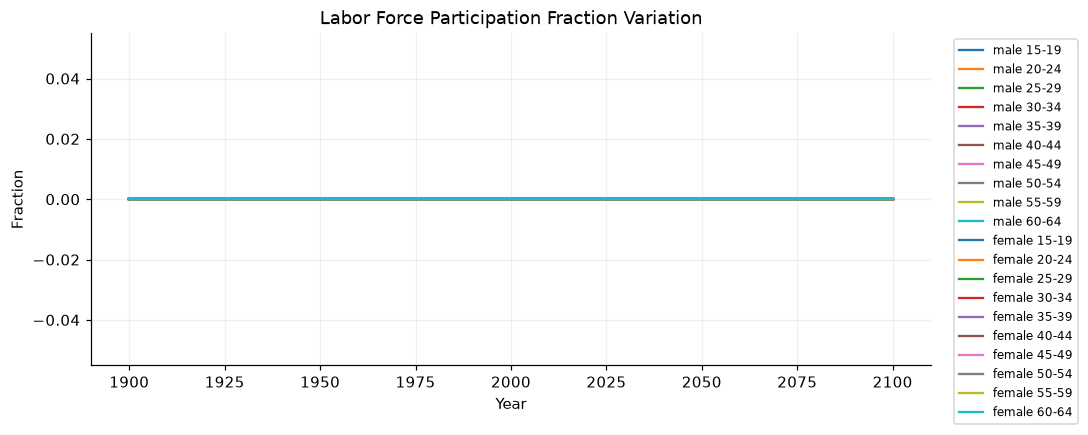

In [11]:
data = result

plt.figure(figsize=(10, 4))
plt.plot(data.index, data['labor_force_participation_fraction_variation[male,"15-19"]'], label='male 15-19', linewidth=1.5)
plt.plot(data.index, data['labor_force_participation_fraction_variation[male,"20-24"]'], label='male 20-24', linewidth=1.5)
plt.plot(data.index, data['labor_force_participation_fraction_variation[male,"25-29"]'], label='male 25-29', linewidth=1.5)
plt.plot(data.index, data['labor_force_participation_fraction_variation[male,"30-34"]'], label='male 30-34', linewidth=1.5)
plt.plot(data.index, data['labor_force_participation_fraction_variation[male,"35-39"]'], label='male 35-39', linewidth=1.5)
plt.plot(data.index, data['labor_force_participation_fraction_variation[male,"40-44"]'], label='male 40-44', linewidth=1.5)
plt.plot(data.index, data['labor_force_participation_fraction_variation[male,"45-49"]'], label='male 45-49', linewidth=1.5)
plt.plot(data.index, data['labor_force_participation_fraction_variation[male,"50-54"]'], label='male 50-54', linewidth=1.5)
plt.plot(data.index, data['labor_force_participation_fraction_variation[male,"55-59"]'], label='male 55-59', linewidth=1.5)
plt.plot(data.index, data['labor_force_participation_fraction_variation[male,"60-64"]'], label='male 60-64', linewidth=1.5)
plt.plot(data.index, data['labor_force_participation_fraction_variation[female,"15-19"]'], label='female 15-19', linewidth=1.5)
plt.plot(data.index, data['labor_force_participation_fraction_variation[female,"20-24"]'], label='female 20-24', linewidth=1.5)
plt.plot(data.index, data['labor_force_participation_fraction_variation[female,"25-29"]'], label='female 25-29', linewidth=1.5)
plt.plot(data.index, data['labor_force_participation_fraction_variation[female,"30-34"]'], label='female 30-34', linewidth=1.5)
plt.plot(data.index, data['labor_force_participation_fraction_variation[female,"35-39"]'], label='female 35-39', linewidth=1.5)
plt.plot(data.index, data['labor_force_participation_fraction_variation[female,"40-44"]'], label='female 40-44', linewidth=1.5)
plt.plot(data.index, data['labor_force_participation_fraction_variation[female,"45-49"]'], label='female 45-49', linewidth=1.5)
plt.plot(data.index, data['labor_force_participation_fraction_variation[female,"50-54"]'], label='female 50-54', linewidth=1.5)
plt.plot(data.index, data['labor_force_participation_fraction_variation[female,"55-59"]'], label='female 55-59', linewidth=1.5)
plt.plot(data.index, data['labor_force_participation_fraction_variation[female,"60-64"]'], label='female 60-64', linewidth=1.5)

plt.title('Labor Force Participation Fraction Variation')
plt.xlabel("Year")
plt.ylabel('Fraction')
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()


### 4.2 Birth Gender Fraction


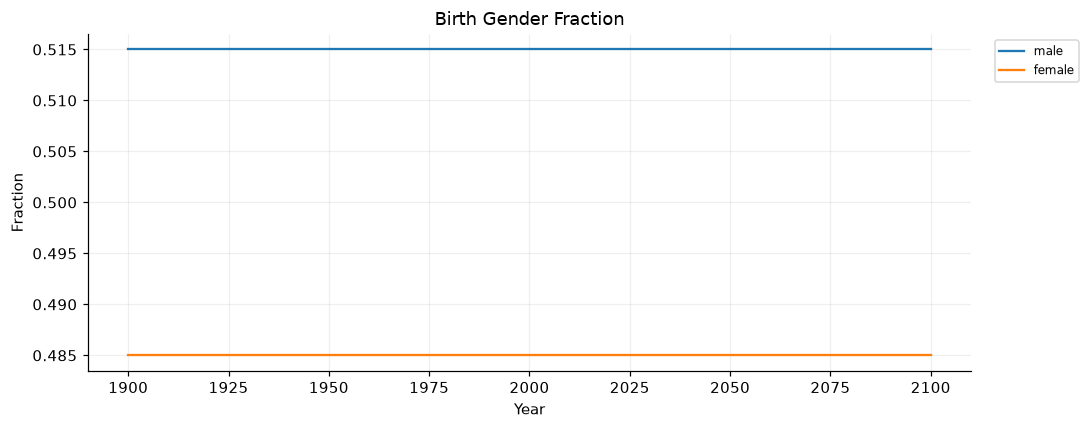

In [12]:
data = result

plt.figure(figsize=(10, 4))
plt.plot(data.index, data['birth_gender_fraction[male]'], label='male', linewidth=1.5)
plt.plot(data.index, data['birth_gender_fraction[female]'], label='female', linewidth=1.5)

plt.title('Birth Gender Fraction')
plt.xlabel("Year")
plt.ylabel('Fraction')
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()


### 4.3 Production rate of animal food


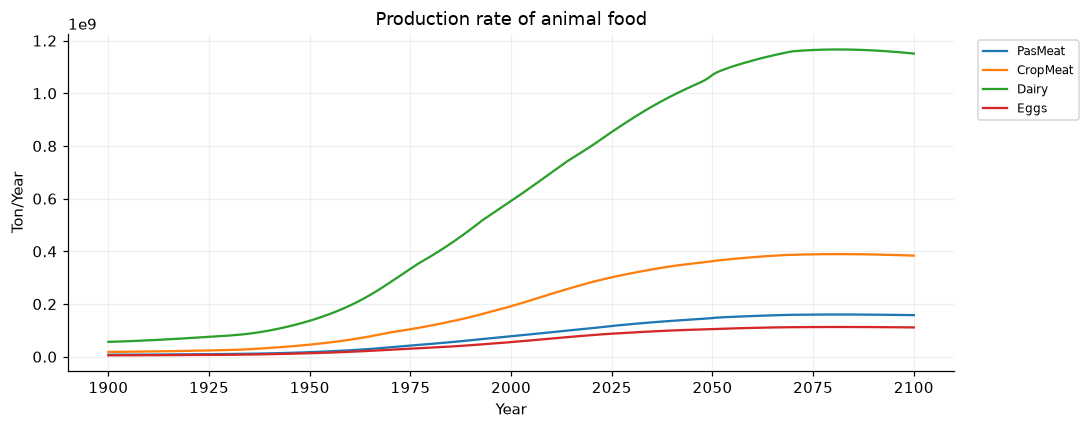

In [13]:
data = result

plt.figure(figsize=(10, 4))
plt.plot(data.index, data['production_rate_of_animal_food[PasMeat]'], label='PasMeat', linewidth=1.5)
plt.plot(data.index, data['production_rate_of_animal_food[CropMeat]'], label='CropMeat', linewidth=1.5)
plt.plot(data.index, data['production_rate_of_animal_food[Dairy]'], label='Dairy', linewidth=1.5)
plt.plot(data.index, data['production_rate_of_animal_food[Eggs]'], label='Eggs', linewidth=1.5)

plt.title('Production rate of animal food')
plt.xlabel("Year")
plt.ylabel('Ton/Year')
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()


### 4.4 Survivors at exact age x


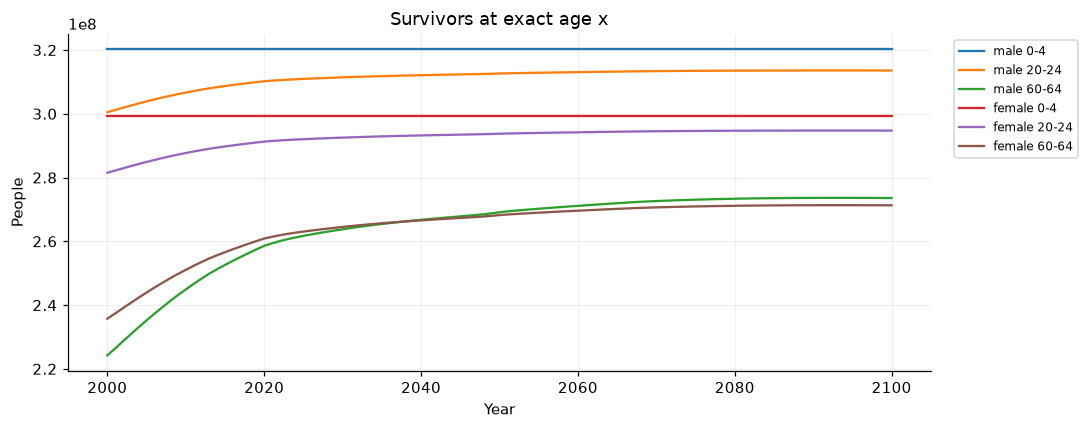

In [14]:
# 仅显示 2000 年及以后；保留男女各三个代表年龄组。
data = result.loc[2000:]

plt.figure(figsize=(10, 4))
plt.plot(data.index, data['survivors_at_exact_age_x[male,"0-4"]'], label='male 0-4', linewidth=1.5)
plt.plot(data.index, data['survivors_at_exact_age_x[male,"20-24"]'], label='male 20-24', linewidth=1.5)
plt.plot(data.index, data['survivors_at_exact_age_x[male,"60-64"]'], label='male 60-64', linewidth=1.5)
plt.plot(data.index, data['survivors_at_exact_age_x[female,"0-4"]'], label='female 0-4', linewidth=1.5)
plt.plot(data.index, data['survivors_at_exact_age_x[female,"20-24"]'], label='female 20-24', linewidth=1.5)
plt.plot(data.index, data['survivors_at_exact_age_x[female,"60-64"]'], label='female 60-64', linewidth=1.5)

plt.title('Survivors at exact age x')
plt.xlabel("Year")
plt.ylabel('People')
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()


### 4.5 Total person years T


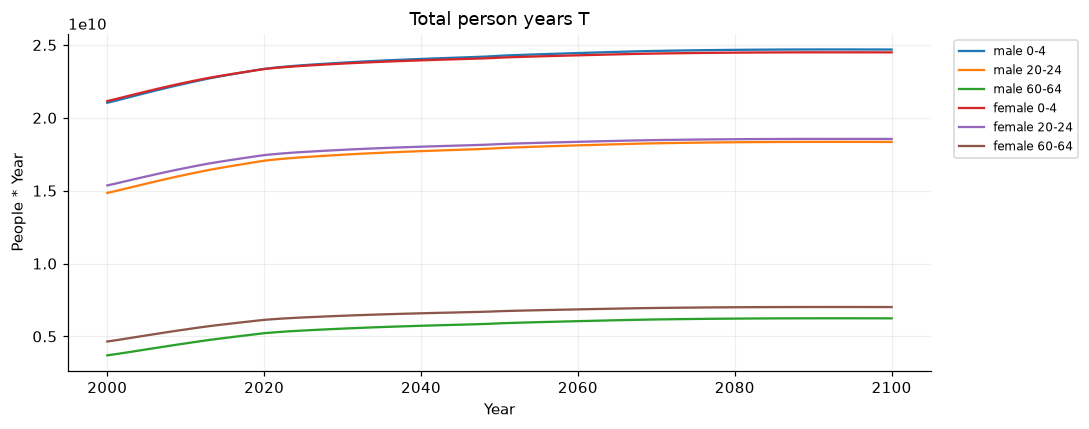

In [15]:
# 仅显示 2000 年及以后；保留男女各三个代表年龄组。
data = result.loc[2000:]

plt.figure(figsize=(10, 4))
plt.plot(data.index, data['total_person_years_t[male,"0-4"]'], label='male 0-4', linewidth=1.5)
plt.plot(data.index, data['total_person_years_t[male,"20-24"]'], label='male 20-24', linewidth=1.5)
plt.plot(data.index, data['total_person_years_t[male,"60-64"]'], label='male 60-64', linewidth=1.5)
plt.plot(data.index, data['total_person_years_t[female,"0-4"]'], label='female 0-4', linewidth=1.5)
plt.plot(data.index, data['total_person_years_t[female,"20-24"]'], label='female 20-24', linewidth=1.5)
plt.plot(data.index, data['total_person_years_t[female,"60-64"]'], label='female 60-64', linewidth=1.5)

plt.title('Total person years T')
plt.xlabel("Year")
plt.ylabel('People * Year')
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()


### 4.6 Total person years of interest pT


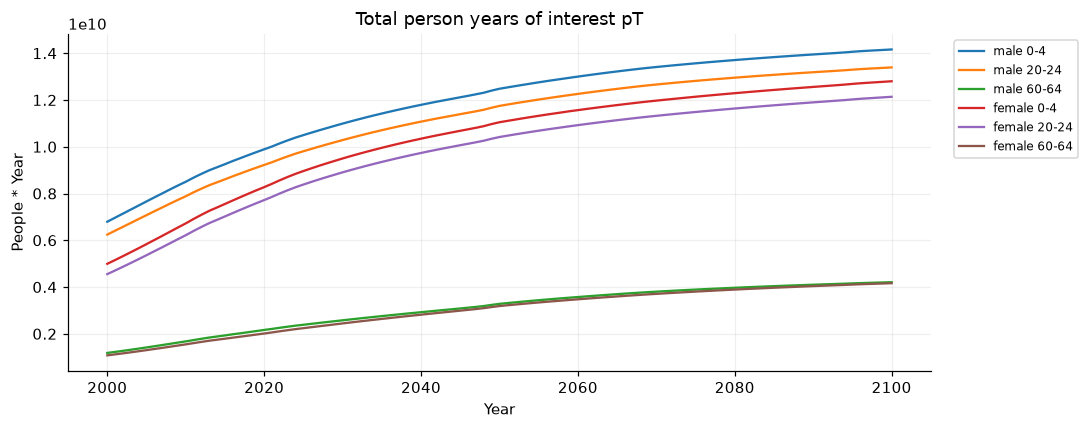

In [16]:
# 仅显示 2000 年及以后；保留男女各三个代表年龄组。
data = result.loc[2000:]

plt.figure(figsize=(10, 4))
plt.plot(data.index, data['total_person_years_of_interest_pt[male,"0-4"]'], label='male 0-4', linewidth=1.5)
plt.plot(data.index, data['total_person_years_of_interest_pt[male,"20-24"]'], label='male 20-24', linewidth=1.5)
plt.plot(data.index, data['total_person_years_of_interest_pt[male,"60-64"]'], label='male 60-64', linewidth=1.5)
plt.plot(data.index, data['total_person_years_of_interest_pt[female,"0-4"]'], label='female 0-4', linewidth=1.5)
plt.plot(data.index, data['total_person_years_of_interest_pt[female,"20-24"]'], label='female 20-24', linewidth=1.5)
plt.plot(data.index, data['total_person_years_of_interest_pt[female,"60-64"]'], label='female 60-64', linewidth=1.5)

plt.title('Total person years of interest pT')
plt.xlabel("Year")
plt.ylabel('People * Year')
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()


### 4.7 Total person years of interest pT POVERTY


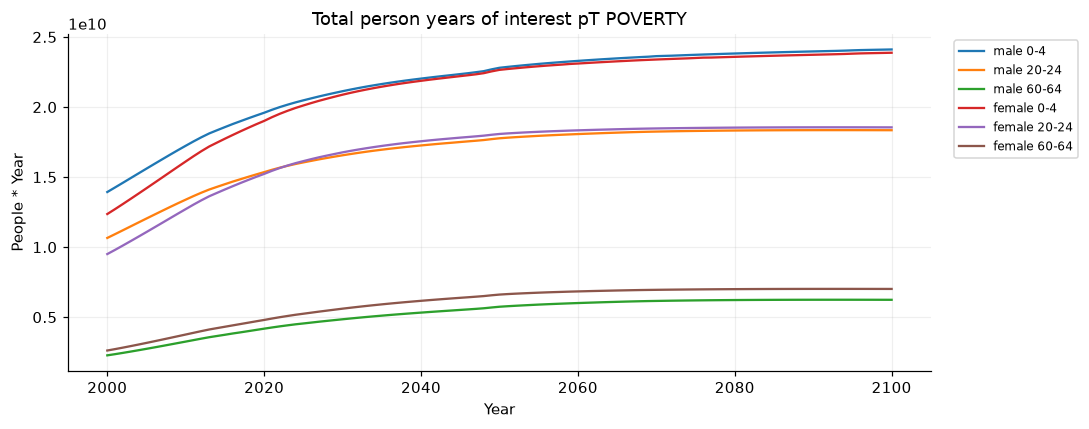

In [17]:
# 仅显示 2000 年及以后；保留男女各三个代表年龄组。
data = result.loc[2000:]

plt.figure(figsize=(10, 4))
plt.plot(data.index, data['total_person_years_of_interest_pt_poverty[male,"0-4"]'], label='male 0-4', linewidth=1.5)
plt.plot(data.index, data['total_person_years_of_interest_pt_poverty[male,"20-24"]'], label='male 20-24', linewidth=1.5)
plt.plot(data.index, data['total_person_years_of_interest_pt_poverty[male,"60-64"]'], label='male 60-64', linewidth=1.5)
plt.plot(data.index, data['total_person_years_of_interest_pt_poverty[female,"0-4"]'], label='female 0-4', linewidth=1.5)
plt.plot(data.index, data['total_person_years_of_interest_pt_poverty[female,"20-24"]'], label='female 20-24', linewidth=1.5)
plt.plot(data.index, data['total_person_years_of_interest_pt_poverty[female,"60-64"]'], label='female 60-64', linewidth=1.5)

plt.title('Total person years of interest pT POVERTY')
plt.xlabel("Year")
plt.ylabel('People * Year')
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()


### 4.8 Total person years of interest pT HEALTH


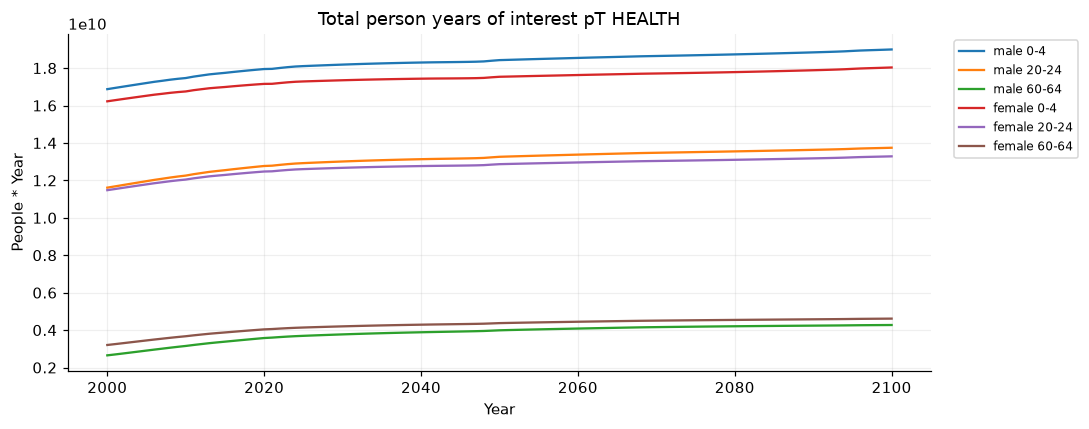

In [18]:
# 仅显示 2000 年及以后；保留男女各三个代表年龄组。
data = result.loc[2000:]

plt.figure(figsize=(10, 4))
plt.plot(data.index, data['total_person_years_of_interest_pt_health[male,"0-4"]'], label='male 0-4', linewidth=1.5)
plt.plot(data.index, data['total_person_years_of_interest_pt_health[male,"20-24"]'], label='male 20-24', linewidth=1.5)
plt.plot(data.index, data['total_person_years_of_interest_pt_health[male,"60-64"]'], label='male 60-64', linewidth=1.5)
plt.plot(data.index, data['total_person_years_of_interest_pt_health[female,"0-4"]'], label='female 0-4', linewidth=1.5)
plt.plot(data.index, data['total_person_years_of_interest_pt_health[female,"20-24"]'], label='female 20-24', linewidth=1.5)
plt.plot(data.index, data['total_person_years_of_interest_pt_health[female,"60-64"]'], label='female 60-64', linewidth=1.5)

plt.title('Total person years of interest pT HEALTH')
plt.xlabel("Year")
plt.ylabel('People * Year')
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()


### 4.9 Total person years of interest pT EDUCATION


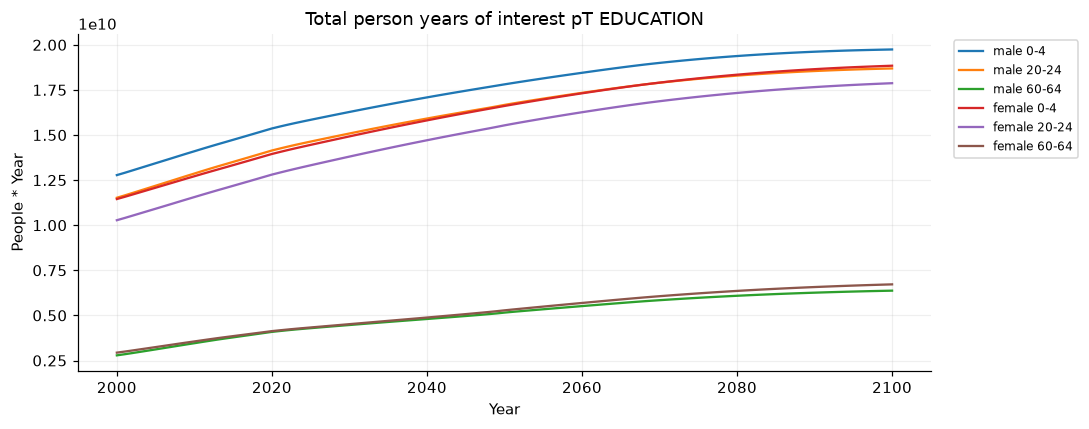

In [19]:
# 仅显示 2000 年及以后；保留男女各三个代表年龄组。
data = result.loc[2000:]

plt.figure(figsize=(10, 4))
plt.plot(data.index, data['total_person_years_of_interest_pt_education[male,"0-4"]'], label='male 0-4', linewidth=1.5)
plt.plot(data.index, data['total_person_years_of_interest_pt_education[male,"20-24"]'], label='male 20-24', linewidth=1.5)
plt.plot(data.index, data['total_person_years_of_interest_pt_education[male,"60-64"]'], label='male 60-64', linewidth=1.5)
plt.plot(data.index, data['total_person_years_of_interest_pt_education[female,"0-4"]'], label='female 0-4', linewidth=1.5)
plt.plot(data.index, data['total_person_years_of_interest_pt_education[female,"20-24"]'], label='female 20-24', linewidth=1.5)
plt.plot(data.index, data['total_person_years_of_interest_pt_education[female,"60-64"]'], label='female 60-64', linewidth=1.5)

plt.title('Total person years of interest pT EDUCATION')
plt.xlabel("Year")
plt.ylabel('People * Year')
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()


In [20]:
# 基本结果检查：全年覆盖、全部有限、出生性别比例之和为 1。
assert np.array_equal(result.index, years)
assert np.isfinite(result.to_numpy()).all()
np.testing.assert_allclose(result[["birth_gender_fraction[male]", "birth_gender_fraction[female]"]].sum(axis=1), 1)
print(f"Checked {len(variables)} variables, {len(result.columns)} subscripted series, {len(result)} annual records.")


Checked 9 variables, 278 subscripted series, 201 annual records.
